# Classificazione multiclasse dei livelli di obesità
**Corso:** Apprendimento Automatico e Apprendimento Profondo  
**Studente:** Luigi Colangelo — **Matricola:** 0322600050  
**Dataset:** UCI Machine Learning Repository, ID 544  

Obiettivo: confrontare i moodelli Logistic Regression, SVM, Random Forest e XGBoost, tutti ottimizzati mediante GridSearchCV a cinque fold rispetto all'F1 macro. Sono inclusi PCA, metriche multiclasse, matrici di confusione, curve ROC one-vs-rest e SHAP.



In [1]:
import json, os, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier
import joblib
sns.set_theme(style='whitegrid')
SEED=42
np.random.seed(SEED)
OUT=Path('risultati_obesita'); OUT.mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| scikit-learn:', __import__('sklearn').__version__)

Python: 3.14.7 | scikit-learn: 1.9.1


## 1. Caricamento Dataset


In [2]:
csv_path=Path('ObesityDataSet_raw_and_data_sinthetic.csv')
try:
    from ucimlrepo import fetch_ucirepo
    ds=fetch_ucirepo(id=544)
    X=ds.data.features.copy()
    y=ds.data.targets.iloc[:, 0].copy()
    print('Fonte: ucimlrepo, ID 544')
    print('Metadata:', ds.metadata.get('name', 'UCI 544'))
except Exception as err:
    if not csv_path.exists():
        raise RuntimeError('Download UCI non riuscito.') from err
    df=pd.read_csv(csv_path)
    X=df.drop(columns=['NObeyesdad']); y=df['NObeyesdad']
    print('Fonte: CSV locale ufficiale; motivo fallback:', str(err)[:100])
assert X.shape[1]==16, f'Attese 16 feature; trovate {X.shape[1]}'
assert y.nunique()==7, f'Attese 7 classi; trovate {y.nunique()}'
print('Dimensioni:', X.shape, '| classi:', y.nunique())
display(pd.concat([X,y.rename('target')],axis=1).head())
print('Valori mancanti:', int(X.isna().sum().sum()), '| righe identiche (feature + target):', int(pd.concat([X,y],axis=1).duplicated().sum()))
display(y.value_counts().rename_axis('Classe').to_frame('N'))

Fonte: ucimlrepo, ID 544
Metadata: Estimation of Obesity Levels Based On Eating Habits and Physical Condition 
Dimensioni: (2111, 16) | classi: 7


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,target
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


Valori mancanti: 0 | righe identiche (feature + target): 24


,N
Classe,
Obesity_Type_I,351
Obesity_Type_III,324
Obesity_Type_II,297
Overweight_Level_I,290
Overweight_Level_II,290
Normal_Weight,287
Insufficient_Weight,272


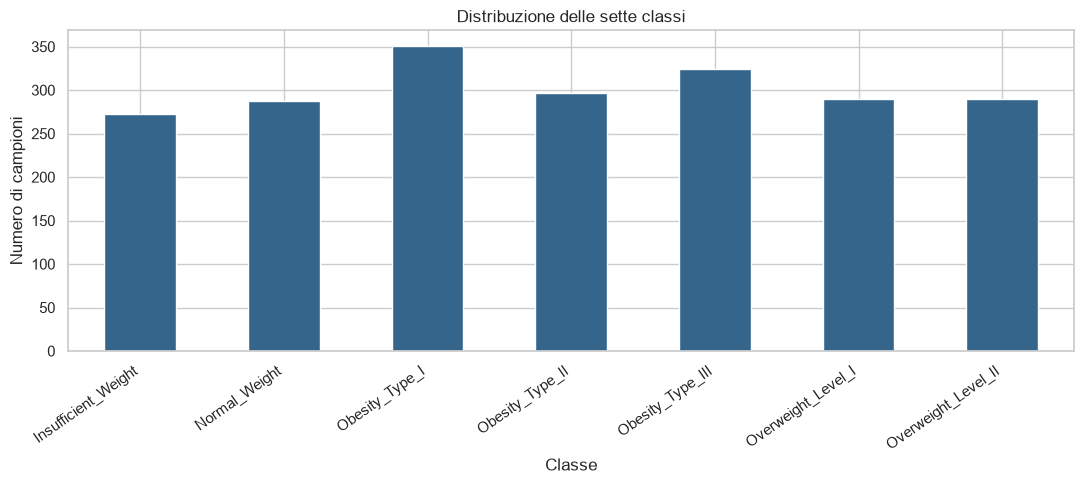

Numeriche: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE'] 
Categoriche: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.313,6.346,14.00,19.947,22.778,26.000,61.00
Height,2111.0,1.702,0.093,1.45,1.630,1.700,1.768,1.98
Weight,2111.0,86.586,26.191,39.00,65.473,83.000,107.431,173.00
FCVC,2111.0,2.419,0.534,1.00,2.000,2.386,3.000,3.00
NCP,2111.0,2.686,0.778,1.00,2.659,3.000,3.000,4.00
CH2O,2111.0,2.008,0.613,1.00,1.585,2.000,2.477,3.00
FAF,2111.0,1.010,0.851,0.00,0.125,1.000,1.667,3.00
TUE,2111.0,0.658,0.609,0.00,0.000,0.625,1.000,2.00


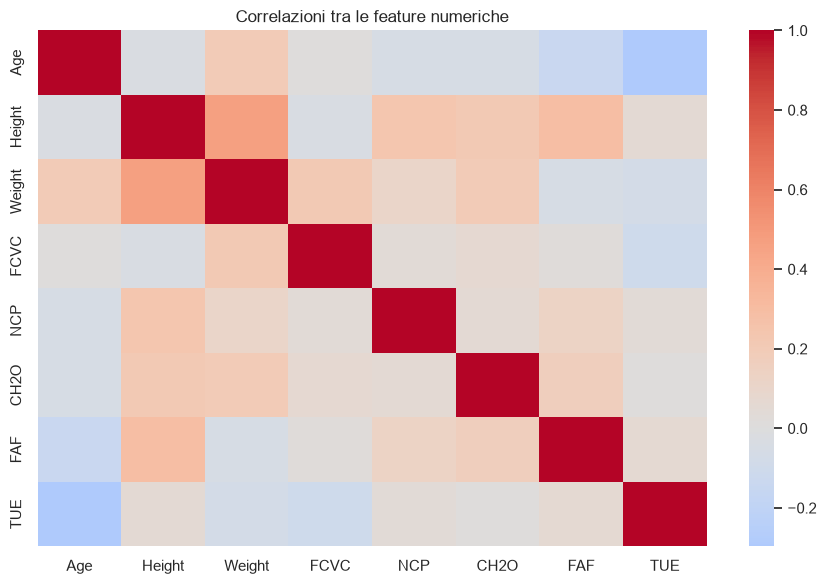

In [3]:
fig,ax=plt.subplots(figsize=(11,5))
y.value_counts().sort_index().plot.bar(ax=ax,color='#35658b')
ax.set(title='Distribuzione delle sette classi',ylabel='Numero di campioni',xlabel='Classe')
plt.xticks(rotation=35,ha='right'); plt.tight_layout(); plt.savefig(OUT/'distribuzione_classi.png',dpi=180); plt.show()
num_cols=X.select_dtypes(include=np.number).columns.tolist()
cat_cols=[c for c in X.columns if c not in num_cols]
print('Numeriche:',num_cols,'\nCategoriche:',cat_cols)
display(X[num_cols].describe().T.round(3))
fig,ax=plt.subplots(figsize=(9,6)); sns.heatmap(X[num_cols].corr(),cmap='coolwarm',center=0,ax=ax)
ax.set_title('Correlazioni tra le feature numeriche'); plt.tight_layout(); plt.savefig(OUT/'correlazioni.png',dpi=180); plt.show()

## 2. Split e preprocessing senza data leakage
Si usa un **test stratificato al 20%**. Il restante 80% è diviso in addestramento **65% del totale** e validazione **15%**. La ricerca con 5-fold è eseguita solo sul train. La validazione serve a scegliere il modello complessivamente migliore, mentre il test rimane intatto. Lo scaling e la codifica one-hot sono appresi **all'interno di ogni fold** attraverso le pipeline.

In [4]:
le=LabelEncoder(); y_enc=le.fit_transform(y)
class_names=le.classes_.tolist(); K=len(class_names)
X_dev,X_test,y_dev,y_test=train_test_split(X,y_enc,test_size=.20,stratify=y_enc,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.1875,stratify=y_dev,random_state=SEED)
print('Train:',len(X_train),'Validation:',len(X_val),'Test:',len(X_test))
print('Etichette:',dict(enumerate(class_names)))
try:
    oh=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:
    oh=OneHotEncoder(handle_unknown='ignore',sparse=False)
num_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())])
cat_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',oh)])
preprocess=ColumnTransformer([('numeric',num_pipe,num_cols),('categorical',cat_pipe,cat_cols)])
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)

Train: 1371 Validation: 317 Test: 423
Etichette: {0: 'Insufficient_Weight', 1: 'Normal_Weight', 2: 'Obesity_Type_I', 3: 'Obesity_Type_II', 4: 'Obesity_Type_III', 5: 'Overweight_Level_I', 6: 'Overweight_Level_II'}


## 3. PCA: analisi delle feature
La PCA è applicata **solo dopo** la codifica e la standardizzazione, e viene adattata **solo sul train**. Si produce un grafico di varianza spiegata e un piano PC1–PC2. La PCA è qui uno strumento descrittivo; **i quattro classificatori utilizzano tutte le feature preprocessate**, non le sole due componenti del grafico.

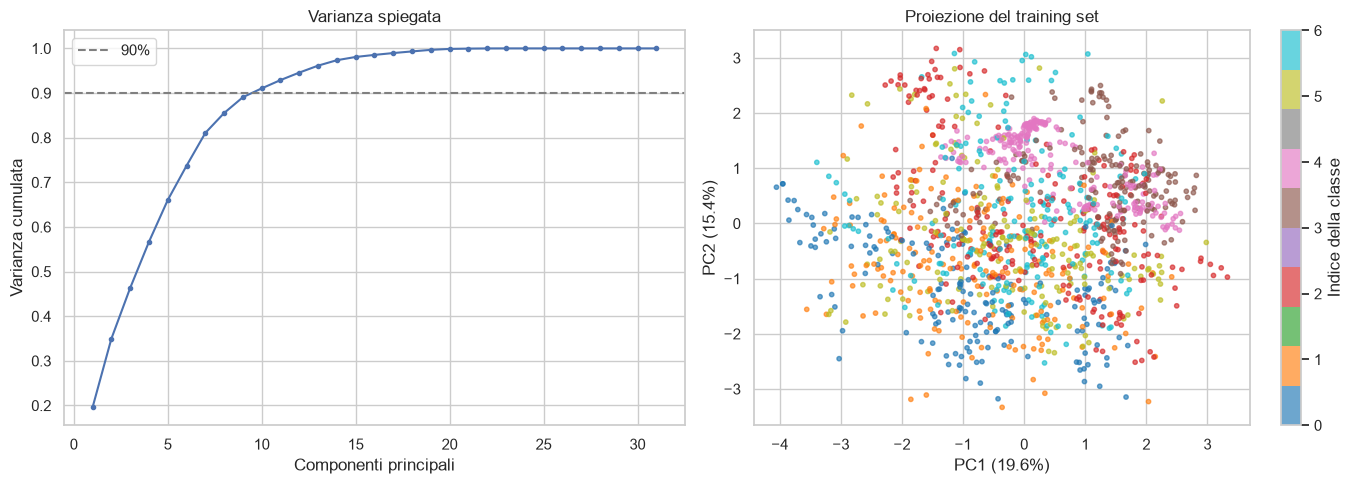

Numero componenti per raggiungere >=90% varianza: 10


,PC1,PC2
numeric__Height,0.606,-0.137
numeric__Weight,0.491,0.349
numeric__CH2O,0.339,-0.026
numeric__NCP,0.275,-0.084
numeric__FAF,0.265,-0.362
categorical__Gender_Male,0.193,-0.083
categorical__Gender_Female,-0.193,0.083
categorical__family_history_with_overweight_no,-0.113,-0.083
categorical__family_history_with_overweight_yes,0.113,0.083
categorical__CAEC_Sometimes,0.074,0.061


In [5]:
Z_train=preprocess.fit_transform(X_train)
Z_val=preprocess.transform(X_val)
feature_names=preprocess.get_feature_names_out()
pca=PCA(random_state=SEED).fit(Z_train)
explained=pca.explained_variance_ratio_
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].plot(np.arange(1,len(explained)+1),np.cumsum(explained),marker='o',ms=3)
axes[0].axhline(.90,ls='--',color='grey',label='90%')
axes[0].set(xlabel='Componenti principali',ylabel='Varianza cumulata',title='Varianza spiegata'); axes[0].legend()
Z2=pca.transform(Z_train)[:,:2]
sc=axes[1].scatter(Z2[:,0],Z2[:,1],c=y_train,cmap='tab10',s=10,alpha=.65)
axes[1].set(xlabel=f'PC1 ({explained[0]:.1%})',ylabel=f'PC2 ({explained[1]:.1%})',title='Proiezione del training set')
fig.colorbar(sc,ax=axes[1],ticks=np.arange(K),label='Indice della classe')
plt.tight_layout(); plt.savefig(OUT/'pca.png',dpi=180); plt.show()
print('Numero componenti per raggiungere >=90% varianza:', int(np.searchsorted(np.cumsum(explained),.90)+1))
loading=pd.DataFrame(pca.components_[:2].T,index=feature_names,columns=['PC1','PC2'])
display(loading.reindex(loading.PC1.abs().sort_values(ascending=False).index).head(12).round(3))

## 4. Quattro modelli: GridSearchCV, 5 fold, F1 macro

In [6]:
models={
    'Logistic Regression': (
        LogisticRegression(max_iter=2500,random_state=SEED),
        {'clf__C':[0.1,1.0,10.0]}),
    'SVM': (
        SVC(kernel='rbf',probability=True,random_state=SEED),
        {'clf__C':[1.0,10.0], 'clf__gamma':['scale',0.1]}),
    'Random Forest': (
        RandomForestClassifier(random_state=SEED,n_jobs=1),
        {'clf__n_estimators':[200,400], 'clf__max_depth':[None,12], 'clf__min_samples_leaf':[1,2]}),
    'XGBoost': (
        XGBClassifier(objective='multi:softprob',num_class=K,eval_metric='mlogloss',
                      random_state=SEED,n_jobs=1,tree_method='hist'),
        {'clf__n_estimators':[150,300], 'clf__max_depth':[3,6], 'clf__learning_rate':[0.05,0.1]})
}
searches={}; val_rows=[]
for name,(classifier,params) in models.items():
    print('\nGrid search:',name,flush=True)
    pipe=Pipeline([('prep',preprocess),('clf',classifier)])
    gs=GridSearchCV(pipe,params,cv=cv,scoring='f1_macro',n_jobs=2,refit=True,
                    return_train_score=False,error_score='raise',verbose=0)
    gs.fit(X_train,y_train)
    searches[name]=gs
    y_pred=gs.predict(X_val)
    val_rows.append({'Modello':name,'CV F1 macro':gs.best_score_,
                     'Validation F1 macro':f1_score(y_val,y_pred,average='macro'),
                     'Validation Accuracy':accuracy_score(y_val,y_pred),
                     'Migliori parametri':str(gs.best_params_)})
    print('CV F1 macro:',round(gs.best_score_,4),'| Validation F1 macro:',round(val_rows[-1]['Validation F1 macro'],4))
val_table=pd.DataFrame(val_rows).sort_values('Validation F1 macro',ascending=False)
display(val_table)
val_table.to_csv(OUT/'validazione_modelli.csv',index=False)
best_name=val_table.iloc[0]['Modello']
print('Modello selezionato in VALIDAZIONE:',best_name)


Grid search: Logistic Regression
CV F1 macro: 0.9282 | Validation F1 macro: 0.9242

Grid search: SVM


C:\Users\ASUS\PycharmProjects\eleborato\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


CV F1 macro: 0.9341 | Validation F1 macro: 0.9604

Grid search: Random Forest
CV F1 macro: 0.9335 | Validation F1 macro: 0.9424

Grid search: XGBoost
CV F1 macro: 0.9687 | Validation F1 macro: 0.9744


,Modello,CV F1 macro,Validation F1 macro,Validation Accuracy,Migliori parametri
3,XGBoost,0.968677,0.974399,0.974763,"{'clf__learning_rate': 0.1, 'clf__max_depth': ..."
1,SVM,0.934075,0.960403,0.962145,"{'clf__C': 10.0, 'clf__gamma': 'scale'}"
2,Random Forest,0.933530,0.942440,0.943218,"{'clf__max_depth': None, 'clf__min_samples_lea..."
0,Logistic Regression,0.928185,0.924170,0.927445,{'clf__C': 10.0}


Modello selezionato in VALIDAZIONE: XGBoost


## 5. Valutazione finale sul test set


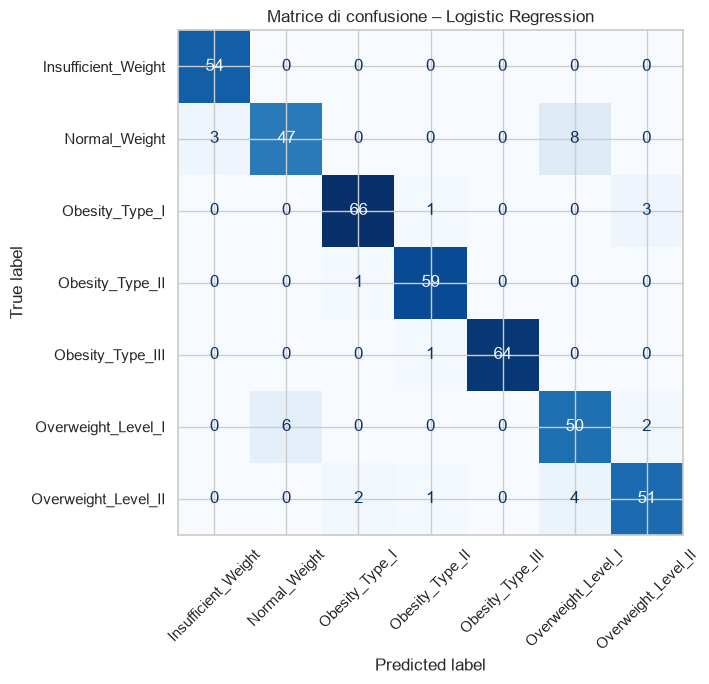

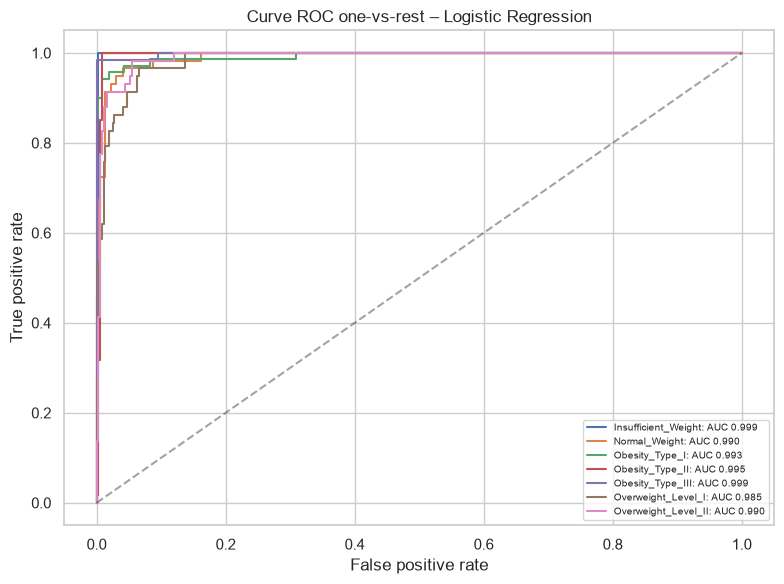

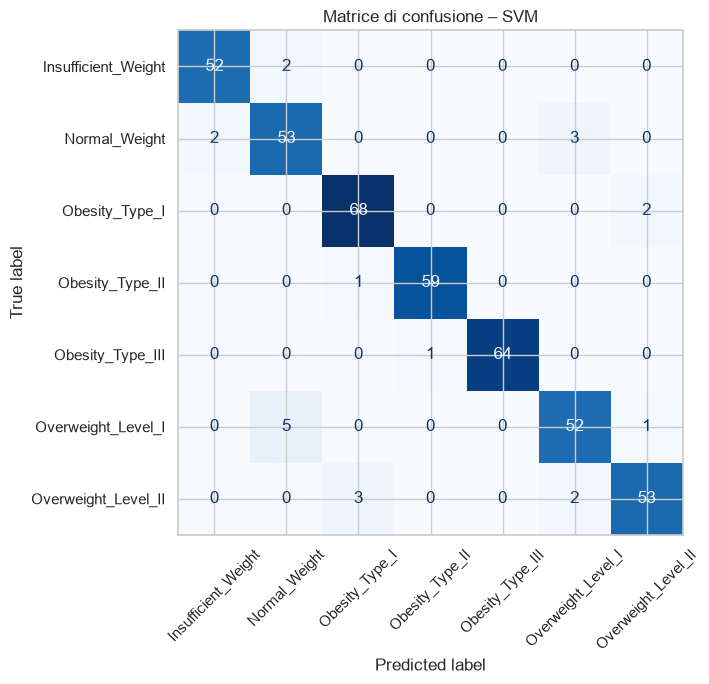

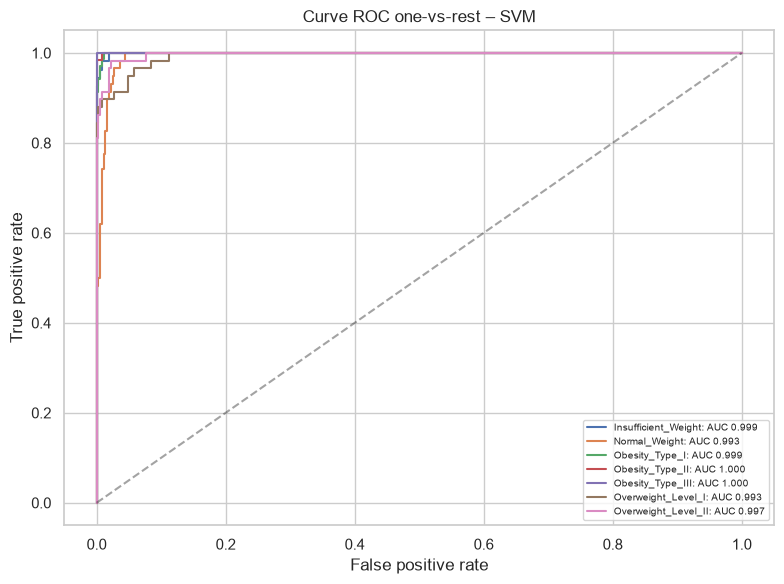

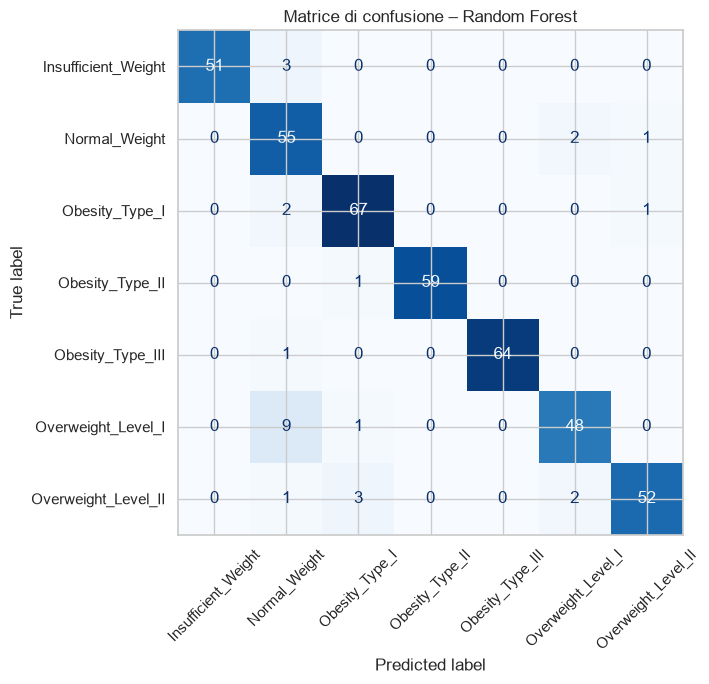

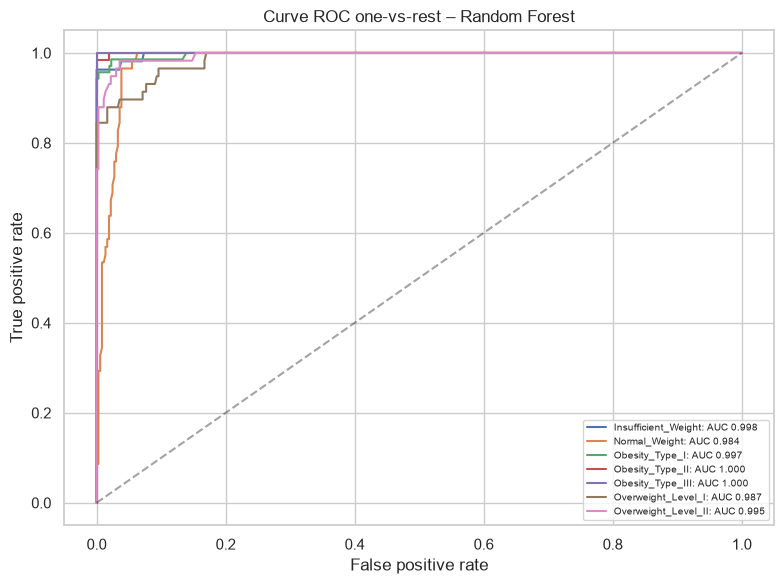

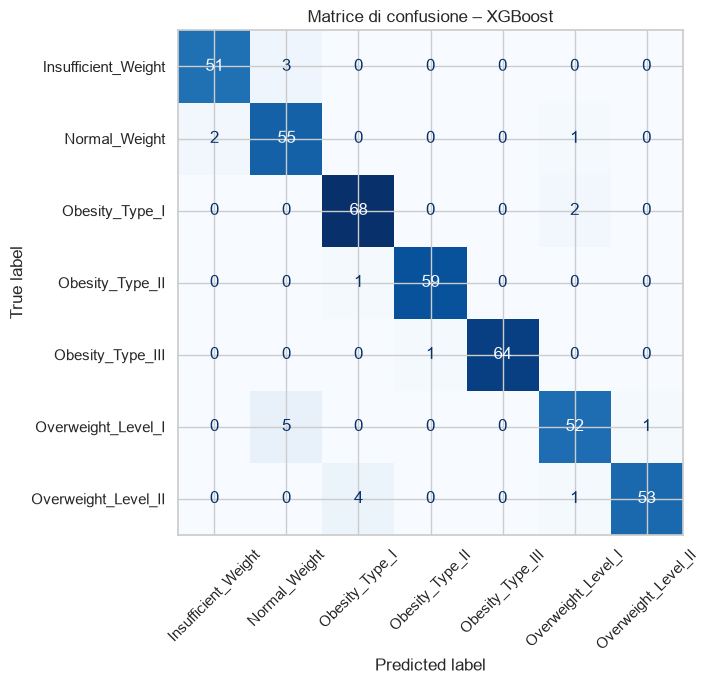

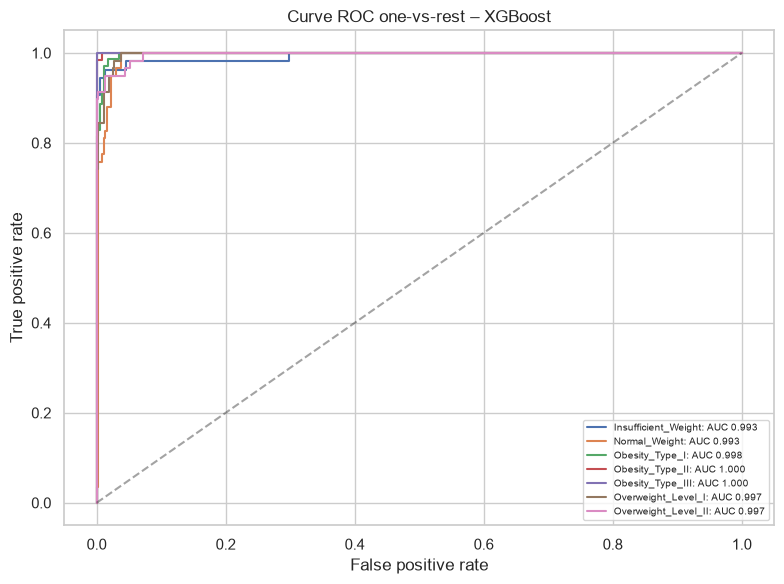

,Modello,Accuracy,Precision macro,Recall macro,F1 macro,ROC AUC macro OvR
3,XGBoost,0.9504,0.9515,0.9489,0.9497,0.9968
1,SVM,0.9480,0.9475,0.9466,0.9470,0.9974
2,Random Forest,0.9362,0.9416,0.9346,0.9361,0.9944
0,Logistic Regression,0.9243,0.9228,0.9232,0.9224,0.9929


Logistic Regression : F1 macro test= 0.9224
SVM : F1 macro test= 0.947
Random Forest : F1 macro test= 0.9361
XGBoost : F1 macro test= 0.9497


In [7]:
test_rows=[]; detailed_reports={}
for name,gs in searches.items():
    pred=gs.predict(X_test)
    prob=gs.predict_proba(X_test)
    assert prob.shape==(len(y_test),K)
    scores={'Modello':name,
       'Accuracy':accuracy_score(y_test,pred),
       'Precision macro':precision_score(y_test,pred,average='macro',zero_division=0),
       'Recall macro':recall_score(y_test,pred,average='macro',zero_division=0),
       'F1 macro':f1_score(y_test,pred,average='macro',zero_division=0),
       'ROC AUC macro OvR':roc_auc_score(y_test,prob,multi_class='ovr',average='macro',labels=np.arange(K))}
    test_rows.append(scores)
    detailed_reports[name]=classification_report(y_test,pred,labels=np.arange(K),target_names=class_names,output_dict=True,zero_division=0)
    cm=confusion_matrix(y_test,pred,labels=np.arange(K))
    fig,ax=plt.subplots(figsize=(9,7))
    ConfusionMatrixDisplay(cm,display_labels=class_names).plot(ax=ax,cmap='Blues',xticks_rotation=45,colorbar=False)
    ax.set_title('Matrice di confusione – '+name)
    fig.tight_layout(); fig.savefig(OUT/('cm_'+name.replace(' ','_')+'.png'),dpi=160); plt.show()
    fig,ax=plt.subplots(figsize=(8,6))
    for i,label in enumerate(class_names):
        binary=(y_test==i).astype(int)
        fpr,tpr,_=roc_curve(binary,prob[:,i])
        ax.plot(fpr,tpr,label=f'{label}: AUC {auc(fpr,tpr):.3f}',lw=1.5)
    ax.plot([0,1],[0,1],'k--',alpha=.4)
    ax.set(xlabel='False positive rate',ylabel='True positive rate',title='Curve ROC one-vs-rest – '+name)
    ax.legend(loc='lower right',fontsize=7)
    fig.tight_layout(); fig.savefig(OUT/('roc_'+name.replace(' ','_')+'.png'),dpi=160); plt.show()
test_table=pd.DataFrame(test_rows).sort_values('F1 macro',ascending=False)
display(test_table.round(4))
test_table.to_csv(OUT/'metriche_test.csv',index=False)
with open(OUT/'report_per_classe.json','w',encoding='utf8') as f:json.dump(detailed_reports,f,indent=2,ensure_ascii=False)
for row in test_rows:
    print(row['Modello'],': F1 macro test=',round(row['F1 macro'],4))

## 6. Spiegabilità SHAP (opzione 5b della traccia)
L'analisi SHAP viene applicata al **Random Forest** ottimizzato, non a una PCA. I contributi sono calcolati sulle colonne **one-hot dopo il preprocessing**. Il grafico mostra la media del valore assoluto dei contributi sulle sette classi e su un sottoinsieme del test. SHAP descrive l'uso delle feature da parte del modello, non stabilisce causalità.

C:\Users\ASUS\PycharmProjects\eleborato\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


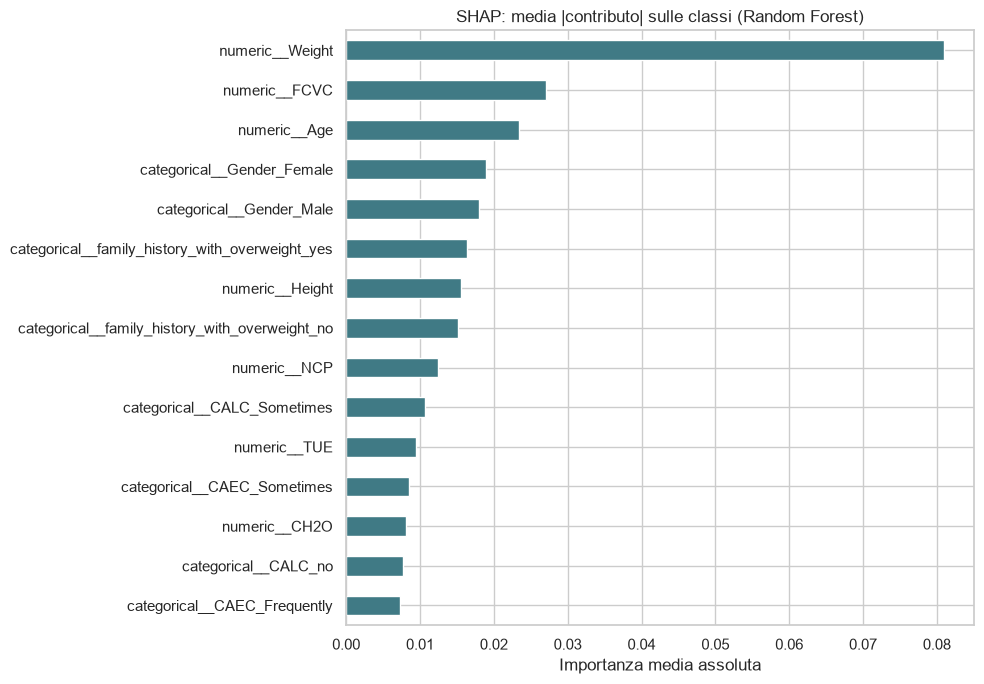

,Mean absolute SHAP
numeric__Weight,0.080979
numeric__FCVC,0.027124
numeric__Age,0.023386
categorical__Gender_Female,0.018977
categorical__Gender_Male,0.018002
categorical__family_history_with_overweight_yes,0.016408
numeric__Height,0.015585
categorical__family_history_with_overweight_no,0.015160
numeric__NCP,0.012415
categorical__CALC_Sometimes,0.010662


In [8]:
import shap
rf_pipe=searches['Random Forest'].best_estimator_
rf_prep=rf_pipe.named_steps['prep']; rf_model=rf_pipe.named_steps['clf']
X_small=X_test.iloc[:min(80,len(X_test))]
Z_small=rf_prep.transform(X_small)
names=rf_prep.get_feature_names_out()
explainer=shap.TreeExplainer(rf_model)
shap_values=explainer.shap_values(Z_small)
# Compatibilità SHAP: lista (una matrice per classe) o ndarray (n,p,k)
if isinstance(shap_values,list):
    importance=np.mean([np.abs(v).mean(axis=0) for v in shap_values],axis=0)
else:
    sv=np.asarray(shap_values)
    if sv.ndim==3:
        importance=np.abs(sv).mean(axis=(0,2))
    elif sv.ndim==2:
        importance=np.abs(sv).mean(axis=0)
    else:
        raise ValueError(f'Forma SHAP inattesa: {sv.shape}')
imp=pd.Series(importance,index=names).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,7))
imp.head(15).sort_values().plot.barh(ax=ax,color='#407a85')
ax.set(title='SHAP: media |contributo| sulle classi (Random Forest)',xlabel='Importanza media assoluta')
fig.tight_layout(); fig.savefig(OUT/'shap_importance.png',dpi=180); plt.show()
display(imp.head(15).to_frame('Mean absolute SHAP'))
imp.to_csv(OUT/'shap_importance.csv',header=['mean_abs_shap'])

## 7. Verifica critica: quanto conta la coppia altezza/peso?
Le classi di obesità sono fortemente legate all'indice di massa corporea. Per capire quanto il risultato dipenda dalla disponibilità di altezza e peso, è utile una **analisi di sensibilità**: riaddestrare il solo Random Forest togliendo `Height` e `Weight` usando il *solo training*, con identica configurazione della ricerca, e confrontare sul test (non usare il risultato per scegliere il modello a posteriori).

In [9]:
X_train_reduced=X_train.drop(columns=['Height','Weight'])
X_test_reduced=X_test.drop(columns=['Height','Weight'])
num_reduced=[c for c in num_cols if c not in ['Height','Weight']]
pre_reduced=ColumnTransformer([('numeric',num_pipe,num_reduced),('categorical',cat_pipe,cat_cols)])
rf_params=searches['Random Forest'].best_params_
rf_reduced=Pipeline([('prep',pre_reduced),('clf',RandomForestClassifier(random_state=SEED,n_jobs=1))])
rf_reduced.set_params(**rf_params)
rf_reduced.fit(X_train_reduced,y_train)
full_pred=rf_pipe.predict(X_test)
reduced_pred=rf_reduced.predict(X_test_reduced)
print('RF completo F1 macro:',round(f1_score(y_test,full_pred,average='macro'),4))
print('RF senza Height/Weight F1 macro:',round(f1_score(y_test,reduced_pred,average='macro'),4))


RF completo F1 macro: 0.9361
RF senza Height/Weight F1 macro: 0.8441
